In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
from pathlib import Path

# Create the charts folder in the main project directory
CHARTS_DIR = Path("../charts")
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

print("Charts folder ready:", CHARTS_DIR.resolve())

Charts folder ready: C:\Users\jhaam\OneDrive\Desktop\SWYNEX-Exploratory-Data-Analysis\charts


In [6]:
data_path = Path("../data/cleaned_dataset.csv")

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Number of rows: 4200
Number of columns: 21


,order_id,order_date,customer_id,customer_name,age,gender,region,city,product_category,product_name,...,unit_price,discount_pct,sales_amount,profit,shipping_cost,payment_method,customer_satisfaction,return_flag,order_status,days_to_ship
0,ORD-03903,2024-08-15,CUST32603,Aarav Mehta,39,Other,Central,Raipur,Groceries,Sugar,...,346.32,0.21,4043.14,289.18,56.04,Debit Card,NaN,True,Returned,7.0
1,ORD-02198,2022-08-16,CUST07881,Sanjay Verma,28,Male,West,Mumbai,Beauty,Sunscreen,...,858.66,0.08,9147.31,5355.56,64.49,Debit Card,5.0,False,Delivered,2.0
2,ORD-01348,2021-08-29,CUST49296,Pooja Sharma,41,Other,West,Surat,Furniture,Sofa,...,25941.32,0.14,110156.97,36956.51,67.65,Debit Card,4.0,False,Delivered,5.0
3,ORD-02076,2022-07-05,CUST05587,Priya Reddy,29,Other,West,Ahmedabad,Furniture,Bed Frame,...,22071.92,0.17,262066.11,66644.99,54.47,EMI,3.0,False,Delivered,4.0
4,ORD-00287,2020-05-07,CUST58035,Ritu Sharma,35,Male,Central,Nagpur,Groceries,Cooking Oil,...,320.06,0.31,323.95,31.38,48.81,Net Banking,4.0,False,Pending,4.0


In [7]:
# 1. Dataset dimensions
print("Dataset shape:", df.shape)

# 2. Column names and data types
print("\nColumn names and data types:")
df.info()

# 3. Missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

# 4. Statistical summary
print("\nStatistical summary:")
display(df.describe())

# 5. Duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (4200, 21)

Column names and data types:
<class 'pandas.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               4200 non-null   str    
 1   order_date             4200 non-null   str    
 2   customer_id            4200 non-null   str    
 3   customer_name          4200 non-null   str    
 4   age                    4200 non-null   int64  
 5   gender                 4200 non-null   str    
 6   region                 4200 non-null   str    
 7   city                   4200 non-null   str    
 8   product_category       4200 non-null   str    
 9   product_name           4200 non-null   str    
 10  quantity               4200 non-null   int64  
 11  unit_price             4200 non-null   float64
 12  discount_pct           4200 non-null   float64
 13  sales_amount           4200 non-null   float64
 14  profit     

,age,quantity,unit_price,discount_pct,sales_amount,profit,shipping_cost,customer_satisfaction,days_to_ship
count,4200.000000,4200.000000,4200.000000,4200.000000,4.200000e+03,4.200000e+03,4198.000000,3854.000000,4090.000000
mean,35.968571,5.486429,10702.729695,0.202138,6.292138e+04,1.179028e+04,63.410748,3.017903,5.522005
std,9.754816,2.859296,17408.776463,0.116126,3.195126e+05,5.335219e+04,18.263250,1.414008,2.849383
min,18.000000,1.000000,50.260000,0.000000,3.945000e+01,1.560000e+00,0.510000,1.000000,1.000000
25%,29.000000,3.000000,680.817500,0.100000,2.472295e+03,7.120700e+02,50.845000,2.000000,3.000000
50%,35.000000,5.000000,2246.005000,0.210000,9.647895e+03,3.169875e+03,63.465000,3.000000,6.000000
75%,42.000000,8.000000,12828.977500,0.300000,5.052485e+04,1.051096e+04,75.665000,4.000000,8.000000
max,72.000000,10.000000,79957.920000,0.400000,1.736031e+07,2.445648e+06,133.350000,5.000000,10.000000



Duplicate rows: 0


In [8]:
# Convert order_date to datetime format
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")

# Extract year and month for trend analysis
df["year"] = df["order_date"].dt.year
df["month"] = df["order_date"].dt.month
df["year_month"] = df["order_date"].dt.to_period("M").astype(str)

# Calculate key business statistics
print("========== KEY BUSINESS STATISTICS ==========")

print("Total orders:", df["order_id"].nunique())
print("Total sales:", round(df["sales_amount"].sum(), 2))
print("Total profit:", round(df["profit"].sum(), 2))
print("Average order sales:", round(df["sales_amount"].mean(), 2))
print("Average profit per record:", round(df["profit"].mean(), 2))
print("Total quantity sold:", df["quantity"].sum())

print("\nDate range:")
print("First order date:", df["order_date"].min())
print("Last order date:", df["order_date"].max())

print("\nProduct categories:")
print(df["product_category"].nunique())

print("\nRegions:")
print(df["region"].nunique())

========== KEY BUSINESS STATISTICS ==========
Total orders: 4200
Total sales: 264269804.54
Total profit: 49519155.07
Average order sales: 62921.38
Average profit per record: 11790.28
Total quantity sold: 23043

Date range:
First order date: 2020-01-01 00:00:00
Last order date: 2024-12-30 00:00:00

Product categories:
7

Regions:
5


In [9]:
# Group sales and profit by product category
category_analysis = (
    df.groupby("product_category")
    .agg(
        total_sales=("sales_amount", "sum"),
        total_profit=("profit", "sum"),
        total_quantity=("quantity", "sum"),
        number_of_records=("order_id", "count")
    )
    .sort_values("total_sales", ascending=False)
)

# Calculate each category's percentage of total sales
category_analysis["sales_percentage"] = (
    category_analysis["total_sales"] / df["sales_amount"].sum() * 100
)

# Display results
display(category_analysis.round(2))

,total_sales,total_profit,total_quantity,number_of_records,sales_percentage
product_category,,,,,
Electronics,1.556426e+08,19107476.57,3398,608,58.90
Furniture,5.670920e+07,16005733.05,3295,576,21.46
Sports,3.168667e+07,6991123.66,3225,614,11.99
Clothing,1.156374e+07,4181201.35,3409,632,4.38
Beauty,3.881089e+06,1748717.37,3270,601,1.47
Books,3.777514e+06,1405701.75,3067,562,1.43
Groceries,1.009020e+06,79201.32,3379,607,0.38


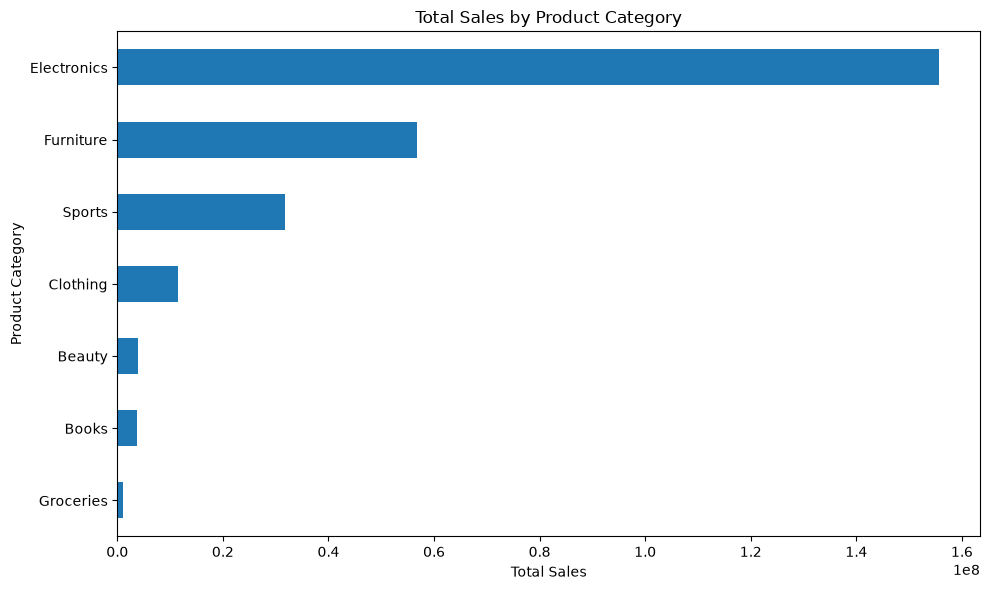

In [10]:
category_analysis["total_sales"].sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Total Sales by Product Category"
)

plt.xlabel("Total Sales")
plt.ylabel("Product Category")
plt.tight_layout()
plt.savefig(
    CHARTS_DIR / "sales_by_category.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [11]:
# Analyze sales and profit by region
region_analysis = (
    df.groupby("region")
    .agg(
        total_sales=("sales_amount", "sum"),
        total_profit=("profit", "sum"),
        total_quantity=("quantity", "sum"),
        number_of_records=("order_id", "count")
    )
    .sort_values("total_sales", ascending=False)
)

region_analysis["sales_percentage"] = (
    region_analysis["total_sales"] / df["sales_amount"].sum() * 100
)

display(region_analysis.round(2))

,total_sales,total_profit,total_quantity,number_of_records,sales_percentage
region,,,,,
South,73519093.83,13261974.24,4800,866,27.82
North,53613030.16,10377562.06,4532,848,20.29
East,48501551.85,8733415.56,4521,833,18.35
West,47962618.16,8862052.09,4875,869,18.15
Central,40673510.54,8284151.12,4315,784,15.39


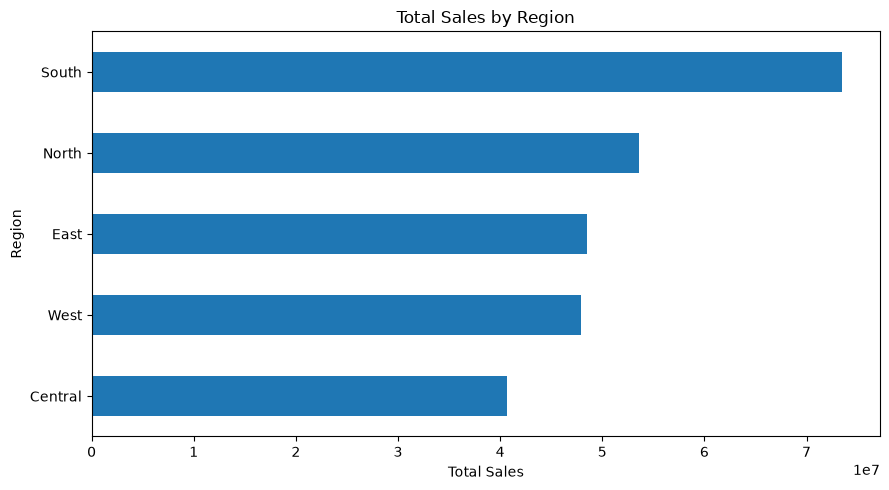

In [28]:
region_analysis["total_sales"].sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Total Sales by Region"
)

plt.xlabel("Total Sales")
plt.ylabel("Region")
plt.tight_layout()
plt.savefig(
    CHARTS_DIR / "sales_by_region.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [13]:
yearly_analysis = (
    df.groupby("year")
    .agg(
        total_sales=("sales_amount", "sum"),
        total_profit=("profit", "sum"),
        number_of_records=("order_id", "count")
    )
)

yearly_analysis["sales_growth_pct"] = (
    yearly_analysis["total_sales"].pct_change() * 100
)

display(yearly_analysis.round(2))

,total_sales,total_profit,number_of_records,sales_growth_pct
year,,,,
2020,41055272.24,7986597.63,804,NaN
2021,57646116.88,11247412.51,836,40.41
2022,50346117.36,9570760.01,883,-12.66
2023,64530469.99,11398158.80,856,28.17
2024,50691828.07,9316226.12,821,-21.45


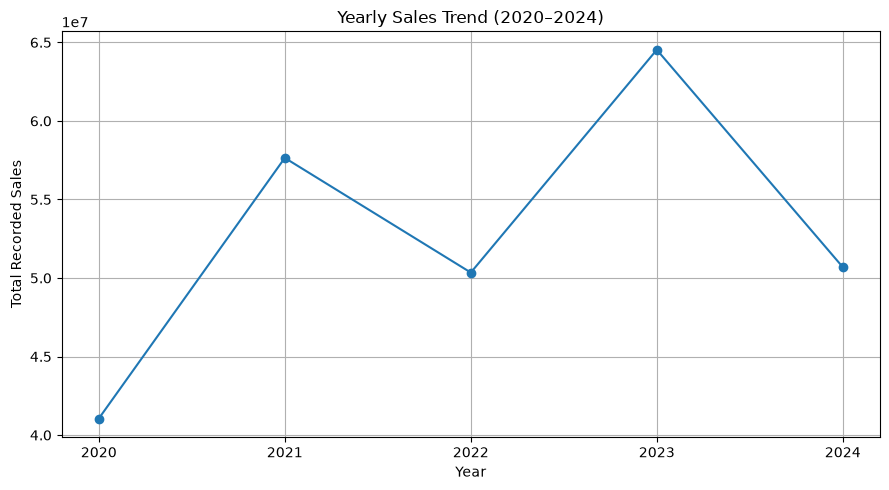

In [29]:
yearly_analysis["total_sales"].plot(
    kind="line",
    marker="o",
    figsize=(9, 5),
    title="Yearly Sales Trend (2020–2024)"
)

plt.xlabel("Year")
plt.ylabel("Total Recorded Sales")
plt.xticks(yearly_analysis.index)
plt.grid(True)
plt.tight_layout()
plt.savefig(
    CHARTS_DIR / "yearly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

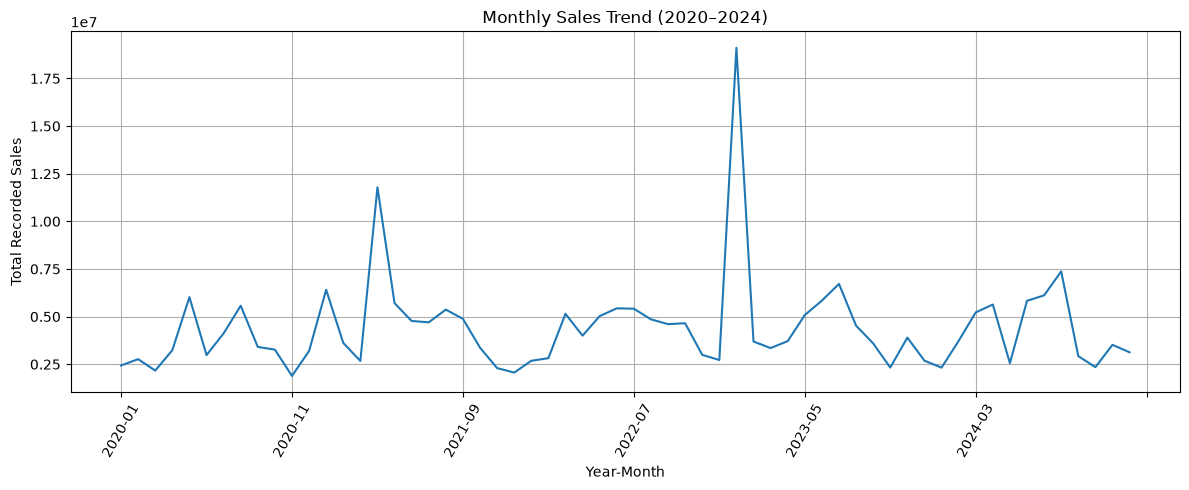

In [30]:
monthly_analysis = (
    df.groupby("year_month")
    .agg(
        total_sales=("sales_amount", "sum"),
        total_profit=("profit", "sum")
    )
)

monthly_analysis["total_sales"].plot(
    kind="line",
    figsize=(12, 5),
    title="Monthly Sales Trend (2020–2024)"
)

plt.xlabel("Year-Month")
plt.ylabel("Total Recorded Sales")
plt.xticks(rotation=60)
plt.grid(True)
plt.tight_layout()
plt.savefig(
    CHARTS_DIR / "monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [16]:
print("Top 5 months by recorded sales:")

display(
    monthly_analysis
    .sort_values("total_sales", ascending=False)
    .head(5)
    .round(2)
)

Top 5 months by recorded sales:


,total_sales,total_profit
year_month,,
2023-01,19112282.79,2818432.88
2021-04,11787068.87,2491626.30
2024-08,7372126.00,1420507.69
2023-07,6715280.53,1097600.28
2021-01,6407917.47,1537329.95


In [17]:
print("Bottom 5 months by recorded sales:")

display(
    monthly_analysis
    .sort_values("total_sales", ascending=True)
    .head(5)
    .round(2)
)

Bottom 5 months by recorded sales:


,total_sales,total_profit
year_month,,
2020-11,1885911.02,292317.61
2021-12,2061895.04,417478.80
2020-03,2167217.16,457814.38
2021-11,2298514.73,431541.64
2024-01,2321163.26,356834.99


In [18]:
# Count and percentage of each order status
status_analysis = df["order_status"].value_counts().to_frame("record_count")

status_analysis["percentage"] = (
    status_analysis["record_count"] / len(df) * 100
)

display(status_analysis.round(2))

,record_count,percentage
order_status,,
Delivered,2731,65.02
Returned,612,14.57
Cancelled,346,8.24
Shipped,327,7.79
Pending,184,4.38


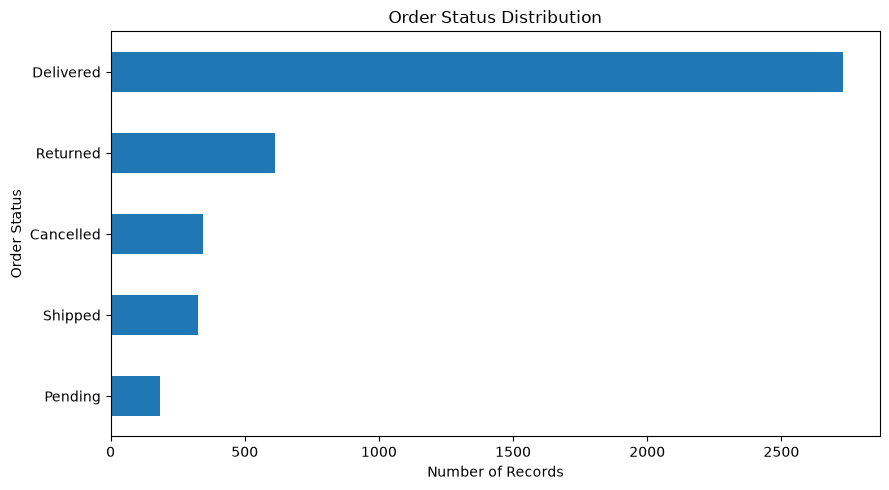

In [31]:
status_analysis["record_count"].sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Order Status Distribution"
)

plt.xlabel("Number of Records")
plt.ylabel("Order Status")
plt.tight_layout()
plt.savefig(
    CHARTS_DIR / "order_status_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [20]:
# Customer satisfaction statistics
print("Customer satisfaction summary:")
print(df["customer_satisfaction"].describe())

print(
    "\nNumber of ratings:",
    df["customer_satisfaction"].count()
)

print(
    "Missing ratings:",
    df["customer_satisfaction"].isna().sum()
)

print(
    "Average customer satisfaction:",
    round(df["customer_satisfaction"].mean(), 2)
)

Customer satisfaction summary:
count    3854.000000
mean        3.017903
std         1.414008
min         1.000000
25%         2.000000
50%         3.000000
75%         4.000000
max         5.000000
Name: customer_satisfaction, dtype: float64

Number of ratings: 3854
Missing ratings: 346
Average customer satisfaction: 3.02


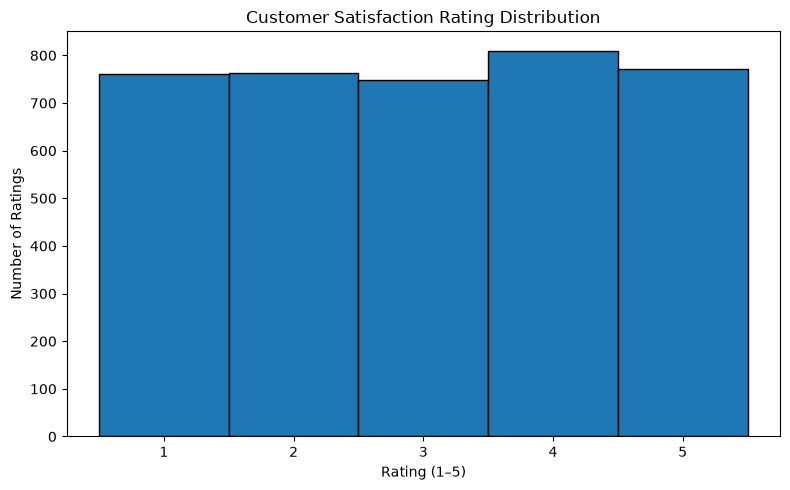

In [32]:
df["customer_satisfaction"].dropna().plot(
    kind="hist",
    bins=np.arange(0.5, 6.5, 1),
    edgecolor="black",
    figsize=(8, 5),
    title="Customer Satisfaction Rating Distribution"
)

plt.xlabel("Rating (1–5)")
plt.ylabel("Number of Ratings")
plt.xticks([1, 2, 3, 4, 5])
plt.tight_layout()
plt.savefig(
    CHARTS_DIR / "customer_satisfaction.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [22]:
satisfaction_by_category = (
    df.groupby("product_category")
    .agg(
        average_rating=("customer_satisfaction", "mean"),
        number_of_ratings=("customer_satisfaction", "count"),
        total_records=("order_id", "count")
    )
    .sort_values("average_rating", ascending=False)
)

display(satisfaction_by_category.round(2))

,average_rating,number_of_ratings,total_records
product_category,,,
Books,3.11,497,562
Clothing,3.06,576,632
Beauty,3.04,558,601
Furniture,3.03,528,576
Electronics,3.00,562,608
Groceries,2.98,561,607
Sports,2.91,572,614


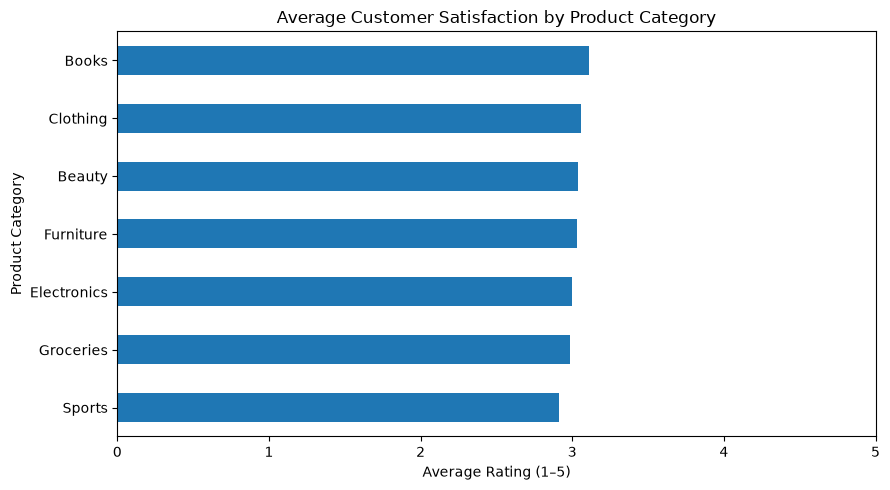

In [ ]:
satisfaction_by_category["average_rating"].sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Average Customer Satisfaction by Product Category"
)

plt.xlabel("Average Rating (1–5)")
plt.ylabel("Product Category")
plt.xlim(0, 5)
plt.tight_layout()
plt.savefig(
    CHARTS_DIR / "satisfaction_by_category.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [24]:
# Identify returned records
df["is_returned"] = df["order_status"].eq("Returned")

# Calculate return counts and percentages by category
returns_by_category = (
    df.groupby("product_category")
    .agg(
        total_records=("order_id", "count"),
        returned_records=("is_returned", "sum")
    )
)

returns_by_category["return_percentage"] = (
    returns_by_category["returned_records"]
    / returns_by_category["total_records"] * 100
)

returns_by_category = returns_by_category.sort_values(
    "return_percentage", ascending=False
)

display(returns_by_category.round(2))

,total_records,returned_records,return_percentage
product_category,,,
Electronics,608,96,15.79
Groceries,607,95,15.65
Sports,614,95,15.47
Clothing,632,88,13.92
Beauty,601,83,13.81
Furniture,576,79,13.72
Books,562,76,13.52


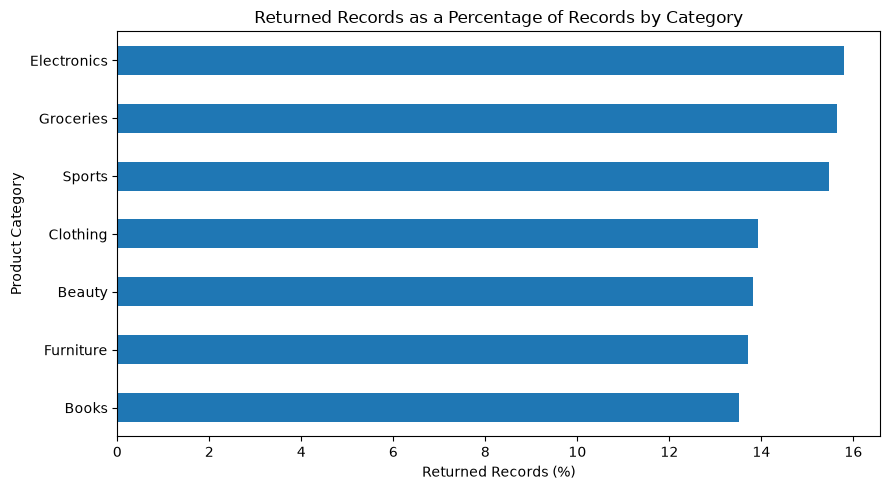

In [33]:
returns_by_category["return_percentage"].sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Returned Records as a Percentage of Records by Category"
)

plt.xlabel("Returned Records (%)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.savefig(
    CHARTS_DIR / "return_by_category.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [26]:
# Inspect the 10 highest recorded sales values
print("TOP 10 RECORDS BY SALES")

display(
    df.nlargest(10, "sales_amount")[
        [
            "order_id",
            "order_date",
            "product_category",
            "region",
            "quantity",
            "unit_price",
            "discount_pct",
            "sales_amount",
            "profit"
        ]
    ].round(2)
)

# Inspect the 10 highest recorded profit values
print("TOP 10 RECORDS BY PROFIT")

display(
    df.nlargest(10, "profit")[
        [
            "order_id",
            "product_category",
            "region",
            "quantity",
            "sales_amount",
            "profit"
        ]
    ].round(2)
)

# Check the overall distribution of sales and profit
print("Sales percentiles:")
print(df["sales_amount"].quantile([0.50, 0.75, 0.90, 0.95, 0.99, 1.00]))

print("\nProfit percentiles:")
print(df["profit"].quantile([0.50, 0.75, 0.90, 0.95, 0.99, 1.00]))

TOP 10 RECORDS BY SALES


C:\Users\jhaam\AppData\Local\Temp\ipykernel_12716\1061061362.py:17: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,order_id,order_date,product_category,region,quantity,unit_price,discount_pct,sales_amount,profit
3784,ORD-02560,2023-01-14,Electronics,South,5,18619.45,0.00,17360314.17,2445648.43
1120,ORD-01025,2021-04-09,Sports,North,5,9380.72,0.29,7936261.20,1739854.00
2536,ORD-00809,2021-01-05,Clothing,South,5,3280.13,0.03,2586345.13,921794.60
1095,ORD-00539,2020-08-25,Clothing,Central,5,2567.40,0.31,2281458.22,899209.60
2337,ORD-03003,2023-07-24,Electronics,South,10,76450.07,0.02,1182709.24,198109.98
2836,ORD-02969,2023-07-08,Electronics,South,10,75218.46,0.11,1071676.26,126516.22
3590,ORD-03792,2024-07-06,Electronics,South,10,63505.68,0.16,1033433.55,141319.32
3036,ORD-02993,2023-07-20,Electronics,South,8,77986.06,0.21,991905.81,116835.79
2355,ORD-03057,2023-08-16,Electronics,East,10,67990.05,0.10,962865.37,103582.22
1329,ORD-01981,2022-05-25,Electronics,East,10,74467.03,0.06,941142.08,81264.87


TOP 10 RECORDS BY PROFIT


,order_id,product_category,region,quantity,sales_amount,profit
3784,ORD-02560,Electronics,South,5,17360314.17,2445648.43
1120,ORD-01025,Sports,North,5,7936261.20,1739854.00
2536,ORD-00809,Clothing,South,5,2586345.13,921794.60
1095,ORD-00539,Clothing,Central,5,2281458.22,899209.60
997,ORD-01242,Books,East,5,729651.06,258878.20
2337,ORD-03003,Electronics,South,10,1182709.24,198109.98
2140,ORD-01732,Books,South,5,533420.31,141347.64
3590,ORD-03792,Electronics,South,10,1033433.55,141319.32
1298,ORD-03751,Electronics,Central,8,832824.46,136279.91
544,ORD-02846,Furniture,South,10,475250.99,133297.06


Sales percentiles:
0.50    9.647895e+03
0.75    5.052485e+04
0.90    1.731096e+05
0.95    2.741691e+05
0.99    5.938812e+05
1.00    1.736031e+07
Name: sales_amount, dtype: float64

Profit percentiles:
0.50    3.169875e+03
0.75    1.051096e+04
0.90    3.141973e+04
0.95    4.837454e+04
0.99    8.985642e+04
1.00    2.445648e+06
Name: profit, dtype: float64


In [27]:
# Calculate expected sales using transaction details
df["calculated_sales"] = (
    df["quantity"] * df["unit_price"] * (1 - df["discount_pct"])
)

# Compare calculated sales with recorded sales
df["sales_difference_pct"] = (
    (df["sales_amount"] - df["calculated_sales"]).abs()
    / df["calculated_sales"].abs().replace(0, np.nan)
) * 100

mismatch_count = (df["sales_difference_pct"] > 10).sum()
top_10_sales = df.nlargest(10, "sales_amount")["sales_amount"].sum()
total_sales = df["sales_amount"].sum()

print(f"Total records: {len(df)}")
print(f"Records with sales mismatch above 10%: {mismatch_count}")
print(f"Percentage of records with mismatch: {mismatch_count / len(df) * 100:.2f}%")
print(f"Top 10 recorded sales combined: {top_10_sales:,.2f}")
print(f"Top 10 as percentage of total recorded sales: {top_10_sales / total_sales * 100:.2f}%")

Total records: 4200
Records with sales mismatch above 10%: 3277
Percentage of records with mismatch: 78.02%
Top 10 recorded sales combined: 36,348,111.03
Top 10 as percentage of total recorded sales: 13.75%
